# Combined Gait Analysis

Compares Empirical, SCAMPER, MIMIC-MJX, and Scratch (PPO from scratch) across Walk (S=0.3 m/s), Trot (S=0.5 m/s), and Gallop (S=0.7 m/s).

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import json
from pathlib import Path
from types import SimpleNamespace

import imageio
import jax
import jax.numpy as jnp
import matplotlib
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import orbax.checkpoint as ocp
import pandas as pd
from brax.training import distribution
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks
from ml_collections import config_dict as ml_config_dict
from omegaconf import OmegaConf
from scipy.ndimage import binary_closing
from scipy.signal import medfilt
from scipy.stats import circmean, circstd

from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import maintain_velocity

from scamper.agent.task_transfer.maintain_velocity.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.maintain_velocity.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.maintain_velocity.scratch_networks import (
    make_scratch_ppo_networks,
)

matplotlib.rcParams["font.family"] = "DM Sans"

E0501 12:07:56.590635 3217669 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0501 12:07:56.591108 3217670 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0501 12:07:56.591172 3217671 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]


In [2]:
# ============================================================
# Configuration for all 9 models
# ============================================================

CONFIGS = [
    {
        "name": "SCAMPER_S3e-1",
        "method": "SCAMPER",
        "gait": "walk",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_015403_017303",
        "checkpoint_step": 25,
        "seed": 0,
        "episode_length": 1000,
        "touch_threshold_palm_l": 0.01,
        "touch_threshold_palm_r": 0.01,
        "touch_threshold_sole_l": 0.5,
        "touch_threshold_sole_r": 0.5,
        "min_stance_gap": 10,
        "mean_gait_t_min": 0,
        "mean_gait_t_max": 1000,
        "mean_gait_time_offset_ms": -150,
        "gait_detection_limb": 0,
        "analysis_start": 50,
        "analysis_end": 1000,
    },
    {
        "name": "MIMIC-MJX_S3e-1",
        "method": "MIMIC-MJX",
        "gait": "walk",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260226_085923_279627",
        "checkpoint_step": 25,
        "seed": 0,
        "episode_length": 1000,
        "touch_threshold_palm_l": 0.01,
        "touch_threshold_palm_r": 0.01,
        "touch_threshold_sole_l": 0.5,
        "touch_threshold_sole_r": 0.5,
        "min_stance_gap": 10,
        "mean_gait_t_min": None,
        "mean_gait_t_max": None,
        "mean_gait_time_offset_ms": -150,
        "gait_detection_limb": 0,
        "analysis_start": 50,
        "analysis_end": 1000,
    },
    {
        "name": "Scratch_S3e-1",
        "method": "Scratch",
        "gait": "walk",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260228_120947_605589",
        "checkpoint_step": 25,
        "seed": 0,
        "episode_length": 1000,
        "touch_threshold_palm_l": 0.01,
        "touch_threshold_palm_r": 0.01,
        "touch_threshold_sole_l": 0.5,
        "touch_threshold_sole_r": 0.5,
        "min_stance_gap": 10,
        "mean_gait_t_min": 0,
        "mean_gait_t_max": 1000,
        "mean_gait_time_offset_ms": -150,
        "gait_detection_limb": 0,
        "analysis_start": 50,
        "analysis_end": 1000,
    },
    {
        "name": "SCAMPER_S5e-1",
        "method": "SCAMPER",
        "gait": "trot",
        "spike_removal_sensor": "palm_L",
        "spike_threshold": 0.01,
        "spike_max_len": 8,
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_054936_177691",
        "checkpoint_step": 24,
        "seed": 0,
        "episode_length": 1000,
        "touch_threshold_palm_l": 0.01,
        "touch_threshold_palm_r": 0.01,
        "touch_threshold_sole_l": 0.5,
        "touch_threshold_sole_r": 0.5,
        "min_stance_gap": 10,
        "mean_gait_t_min": 0,
        "mean_gait_t_max": 1000,
        "mean_gait_time_offset_ms": -180,
        "gait_detection_limb": 0,
        "analysis_start": 50,
        "analysis_end": 1000,
    },
    {
        "name": "MIMIC-MJX_S5e-1",
        "method": "MIMIC-MJX",
        "gait": "trot",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260226_090851_633008",
        "checkpoint_step": 23,
        "seed": 0,
        "episode_length": 1000,
        "touch_threshold_palm_l": 0.01,
        "touch_threshold_palm_r": 0.01,
        "touch_threshold_sole_l": 0.5,
        "touch_threshold_sole_r": 0.5,
        "min_stance_gap": 6,
        "mean_gait_t_min": None,
        "mean_gait_t_max": None,
        "mean_gait_time_offset_ms": -150,
        "gait_detection_limb": 0,
        "analysis_start": 50,
        "analysis_end": 1000,
    },
    {
        "name": "Scratch_S5e-1",
        "method": "Scratch",
        "gait": "trot",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260228_120949_207733",
        "checkpoint_step": 25,
        "seed": 0,
        "episode_length": 1000,
        "touch_threshold_palm_l": 0.01,
        "touch_threshold_palm_r": 0.01,
        "touch_threshold_sole_l": 0.5,
        "touch_threshold_sole_r": 0.5,
        "min_stance_gap": 10,
        "mean_gait_t_min": 0,
        "mean_gait_t_max": 1000,
        "mean_gait_time_offset_ms": -150,
        "gait_detection_limb": 0,
        "analysis_start": 50,
        "analysis_end": 1000,
    },
    {
        "name": "SCAMPER_S7e-1",
        "method": "SCAMPER",
        "gait": "gallop",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260403_054936_245874",
        "checkpoint_step": 23,
        "seed": 0,
        "episode_length": 1000,
        "touch_threshold_palm_l": 0.01,
        "touch_threshold_palm_r": 0.01,
        "touch_threshold_sole_l": 1.0,
        "touch_threshold_sole_r": 1.0,
        "min_stance_gap": 6,
        "mean_gait_t_min": 0,
        "mean_gait_t_max": 1000,
        "mean_gait_time_offset_ms": -260,
        "gait_detection_limb": 0,
        "analysis_start": 50,
        "analysis_end": 1000,
    },
    {
        "name": "MIMIC-MJX_S7e-1",
        "method": "MIMIC-MJX",
        "gait": "gallop",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260226_090849_117360",
        "checkpoint_step": 23,
        "seed": 0,
        "episode_length": 1000,
        "touch_threshold_palm_l": 0.01,
        "touch_threshold_palm_r": 0.01,
        "touch_threshold_sole_l": 1.0,
        "touch_threshold_sole_r": 1.0,
        "min_stance_gap": 6,
        "mean_gait_t_min": None,
        "mean_gait_t_max": None,
        "mean_gait_time_offset_ms": -150,
        "gait_detection_limb": 0,
        "analysis_start": 50,
        "analysis_end": 1000,
    },
    {
        "name": "Scratch_S7e-1",
        "method": "Scratch",
        "gait": "gallop",
        "checkpoint_path": "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260228_115525_352293",
        "checkpoint_step": 25,
        "seed": 0,
        "episode_length": 1000,
        "touch_threshold_palm_l": 0.01,
        "touch_threshold_palm_r": 0.01,
        "touch_threshold_sole_l": 1.0,
        "touch_threshold_sole_r": 1.0,
        "min_stance_gap": 6,
        "mean_gait_t_min": 0,
        "mean_gait_t_max": 1000,
        "mean_gait_time_offset_ms": -150,
        "gait_detection_limb": 0,
        "analysis_start": 50,
        "analysis_end": 1000,
    },
]

# Rendering parameters
RENDER_CAMERA = "close_profile-rodent"
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50

# Toggle: True = generate fresh rollouts, False = load saved npz files
GENERATE_NEW_ROLLOUTS = False
RENDER_VIDEOS = False

# Output directories
DATA_BASE_DIR = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis"
)
PLOT_DIR = Path(
    "/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots"
)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Empirical gait filter mapping: notebook gait name -> df_phases.gaits_all2 value
EMPIRICAL_GAIT_FILTER = {
    "walk": "walk_lat",
    "trot": "trot",
    "gallop": "trans_1",
}

# Empirical data path
EMPIRICAL_DATA_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/df_phases.h5"


In [3]:
# ============================================================
# Helper functions
# ============================================================


def find_gait_cycles(
    contact_barcode,
    limb_index=1,
    start_time=0,
    end_time=None,
    min_cycle_length=20,
):
    """
    Find gait cycles based on stance phase onsets.

    Args:
        contact_barcode: Shape [4, timesteps] contact data
        limb_index: Which limb to use for detection (0=RH, 1=RF, 2=LF, 3=LH)
        start_time: Start of analysis window
        end_time: End of analysis window (None = end of data)
        min_cycle_length: Minimum valid cycle length in timesteps

    Returns:
        List of (cycle_start, cycle_end) tuples
    """
    if end_time is None:
        end_time = contact_barcode.shape[1]

    contacts = contact_barcode[limb_index, start_time:end_time]

    # Find stance onsets (transitions from 0 to 1)
    stance_onsets = []
    for i in range(1, len(contacts)):
        if contacts[i - 1] == 0 and contacts[i] == 1:
            stance_onsets.append(start_time + i)

    # Filter out onsets that are too close together
    filtered_onsets = []
    if len(stance_onsets) > 0:
        filtered_onsets.append(stance_onsets[0])
        for onset in stance_onsets[1:]:
            if onset - filtered_onsets[-1] >= min_cycle_length:
                filtered_onsets.append(onset)

    # Create gait cycles from consecutive stance onsets
    gait_cycles = []
    for i in range(len(filtered_onsets) - 1):
        cycle_start = filtered_onsets[i]
        cycle_end = filtered_onsets[i + 1]
        if cycle_end - cycle_start >= min_cycle_length:
            gait_cycles.append((cycle_start, cycle_end))

    return gait_cycles


# Mapping from limb_index to foot body index (for xpos extraction)
# Barcode order: [RH, RF, LF, LH]
limb_to_body_mapping = {
    0: 17,  # RH (Right Hind = sole_R) -> foot_R body
    1: 66,  # RF (Right Front = palm_R) -> hand_R body
    2: 61,  # LF (Left Front = palm_L) -> hand_L body
    3: 13,  # LH (Left Hind = sole_L) -> foot_L body
}


def compute_gait_metrics(
    rollout,
    contact_barcode,
    gait_cycles,
    limb_index=1,
    ctrl_dt=0.02,
):
    """
    Compute gait metrics for each gait cycle.

    Returns dict with:
    - stride_length_mm: List of stride lengths in mm
    - velocity_cm_per_sec: List of velocities in cm/s
    - cadence_steps_per_min: List of cadences in steps/min (true cadence = 2x stride freq)
    - stance_percentage: List of stance percentages
    - cycle_lengths: List of cycle lengths in timesteps
    """
    foot_body_idx = limb_to_body_mapping.get(limb_index)

    metrics = {
        "stride_length_mm": [],
        "velocity_cm_per_sec": [],
        "cadence_steps_per_min": [],
        "stance_percentage": [],
        "cycle_lengths": [],
    }

    smooth_contacts = contact_barcode[limb_index, :]

    for cycle_start, cycle_end in gait_cycles:
        cycle_length = cycle_end - cycle_start
        metrics["cycle_lengths"].append(cycle_length)

        # 1. Stride Length (mm)
        if foot_body_idx is not None:
            foot_pos_start = np.array(rollout[cycle_start].data.xpos[foot_body_idx])
            foot_pos_end = np.array(rollout[cycle_end].data.xpos[foot_body_idx])
            stride_length_m = np.linalg.norm(foot_pos_end - foot_pos_start)
            stride_length_mm = stride_length_m * 1000.0
            metrics["stride_length_mm"].append(stride_length_mm)

            # 2. Velocity (cm/sec)
            cycle_duration_sec = cycle_length * ctrl_dt
            velocity_m_per_sec = stride_length_m / cycle_duration_sec
            velocity_cm_per_sec = velocity_m_per_sec * 100.0
            metrics["velocity_cm_per_sec"].append(velocity_cm_per_sec)

            # 3. Cadence (steps/min)
            stride_freq = 1.0 / cycle_duration_sec
            cadence_steps_per_min = stride_freq * 2.0 * 60.0
            metrics["cadence_steps_per_min"].append(cadence_steps_per_min)

        # 4. Stance Percentage
        cycle_contacts = smooth_contacts[cycle_start:cycle_end]
        stance_pct = 100.0 * np.sum(cycle_contacts) / len(cycle_contacts)
        metrics["stance_percentage"].append(stance_pct)

    return metrics


def extract_touch_sensors(rollout, mj_model):
    """
    Extract palm_L, palm_R, sole_L, sole_R touch sensor data from rollout.

    Returns:
        Tuple of (palm_L, palm_R, sole_L, sole_R) numpy arrays, each shape [T].
    """
    # Find touch sensor indices in sensordata
    touch_sensors = {}
    for i in range(mj_model.nsensor):
        name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_SENSOR, i)
        if name and ("palm" in name.lower() or "sole" in name.lower()):
            sensor_adr = mj_model.sensor_adr[i]
            sensor_dim = mj_model.sensor_dim[i]
            touch_sensors[name] = {"idx": sensor_adr, "dim": sensor_dim}

    PALM_L_IDX = touch_sensors.get("palm_L-rodent", {}).get("idx", 9)
    PALM_R_IDX = touch_sensors.get("palm_R-rodent", {}).get("idx", 10)
    SOLE_L_IDX = touch_sensors.get("sole_L-rodent", {}).get("idx", 11)
    SOLE_R_IDX = touch_sensors.get("sole_R-rodent", {}).get("idx", 12)

    num_timesteps = len(rollout)
    palm_L = np.zeros(num_timesteps)
    palm_R = np.zeros(num_timesteps)
    sole_L = np.zeros(num_timesteps)
    sole_R = np.zeros(num_timesteps)

    for t, state in enumerate(rollout):
        sensordata = np.array(state.data.sensordata)
        palm_L[t] = sensordata[PALM_L_IDX]
        palm_R[t] = sensordata[PALM_R_IDX]
        sole_L[t] = sensordata[SOLE_L_IDX]
        sole_R[t] = sensordata[SOLE_R_IDX]

    return palm_L, palm_R, sole_L, sole_R


def compute_contact_barcode(palm_L, palm_R, sole_L, sole_R, cfg):
    """
    Apply thresholds, median filtering, binary closing, and stack into
    [4, T] barcode. Order: RH=sole_R, RF=palm_R, LF=palm_L, LH=sole_L.
    """
    # Smooth with median filter (kernel=1 = no-op, matches notebooks)
    palm_L_s = medfilt(palm_L, kernel_size=1)
    palm_R_s = medfilt(palm_R, kernel_size=1)
    sole_L_s = medfilt(sole_L, kernel_size=1)
    sole_R_s = medfilt(sole_R, kernel_size=1)

    # Spike removal: zero out brief above-threshold bouts on a target sensor
    if cfg.get("spike_removal_sensor"):
        sensor_map = {
            "palm_L": palm_L_s,
            "palm_R": palm_R_s,
            "sole_L": sole_L_s,
            "sole_R": sole_R_s,
        }
        target = sensor_map[cfg["spike_removal_sensor"]]
        spike_thr = cfg["spike_threshold"]
        spike_max = cfg["spike_max_len"]
        above = (target > spike_thr).astype(int)
        diffs = np.diff(np.concatenate(([0], above, [0])))
        starts = np.where(diffs == 1)[0]
        ends = np.where(diffs == -1)[0]
        n_removed = 0
        for s, e in zip(starts, ends):
            if (e - s) <= spike_max:
                target[s:e] = 0.0
                n_removed += 1
        print(
            f"    Removed {n_removed} brief {cfg['spike_removal_sensor']} spikes (max_len={spike_max})"
        )

    # Threshold
    stance_palm_L = (palm_L_s > cfg["touch_threshold_palm_l"]).astype(int)
    stance_palm_R = (palm_R_s > cfg["touch_threshold_palm_r"]).astype(int)
    stance_sole_L = (sole_L_s > cfg["touch_threshold_sole_l"]).astype(int)
    stance_sole_R = (sole_R_s > cfg["touch_threshold_sole_r"]).astype(int)

    # Binary closing to fill brief gaps
    structure = np.ones(cfg["min_stance_gap"])
    stance_palm_L = binary_closing(stance_palm_L, structure=structure).astype(int)
    stance_palm_R = binary_closing(stance_palm_R, structure=structure).astype(int)
    stance_sole_L = binary_closing(stance_sole_L, structure=structure).astype(int)
    stance_sole_R = binary_closing(stance_sole_R, structure=structure).astype(int)

    # Stack: [RH, RF, LF, LH]
    contact_barcode = np.stack(
        [stance_sole_R, stance_palm_R, stance_palm_L, stance_sole_L], axis=0
    )
    return contact_barcode


def compute_mean_gait_params(contact_barcode, ctrl_dt_ms, t_min, t_max):
    """
    Compute stance durations, phase offsets, mean stride period per limb.

    Returns dict with:
    - means: {limb_name: mean_stance_ms}
    - stds: {limb_name: std_stance_ms}
    - cycle_len_ms: mean stride period in ms
    - phase_offsets_ms: {limb_name: mean_phase_offset_ms}
    """
    limb_names = ["RH", "RF", "LF", "LH"]

    stance_durations = {}
    stance_starts = {}
    stride_periods = {}

    for i, name in enumerate(limb_names):
        signal = contact_barcode[i]
        total_len = len(signal)

        win_start = max(0, min(t_min if t_min is not None else 0, total_len))
        win_end = max(
            win_start, min(t_max if t_max is not None else total_len, total_len)
        )

        windowed = signal[win_start:win_end]

        if len(windowed) == 0:
            stance_starts[name] = np.array([])
            stance_durations[name] = np.array([])
            stride_periods[name] = np.array([])
            continue

        starts = []
        durations = []
        in_stance = False
        bout_start = 0
        bout_len = 0
        first_bout_cutoff = windowed[0] == 1
        is_first_bout = True

        for t, val in enumerate(windowed):
            if val == 1:
                if not in_stance:
                    bout_start = win_start + t
                    in_stance = True
                    bout_len = 1
                else:
                    bout_len += 1
            else:
                if in_stance:
                    if is_first_bout and first_bout_cutoff:
                        is_first_bout = False
                    else:
                        starts.append(bout_start)
                        durations.append(bout_len)
                        is_first_bout = False
                    bout_len = 0
                    in_stance = False

        # If still in stance at end of window, skip (cut off at t_max)

        stance_starts[name] = np.array(starts)
        stance_durations[name] = np.array(durations)
        if len(starts) > 1:
            stride_periods[name] = np.diff(starts)
        else:
            stride_periods[name] = np.array([])

    # Compute stats
    valid_limbs = [name for name in limb_names if len(stance_durations[name]) > 0]
    if len(valid_limbs) == 0:
        raise ValueError("No complete stance bouts found in the analysis window.")

    means = {name: stance_durations[name].mean() * ctrl_dt_ms for name in valid_limbs}
    stds = {name: stance_durations[name].std() * ctrl_dt_ms for name in valid_limbs}

    valid_stride_limbs = [name for name in limb_names if len(stride_periods[name]) > 0]
    if len(valid_stride_limbs) > 0:
        mean_stride = np.mean(
            [stride_periods[name].mean() for name in valid_stride_limbs]
        )
    else:
        raise ValueError("Need >=2 complete stance bouts on at least one limb.")

    # Phase offsets relative to first limb (RH)
    ref_starts = stance_starts[limb_names[0]]
    phase_offsets = {}
    for name in limb_names:
        offsets = []
        if len(ref_starts) > 0:
            for s in stance_starts[name]:
                diffs = s - ref_starts
                valid = diffs[diffs >= 0]
                if len(valid) > 0:
                    offsets.append(valid.min())
        phase_offsets[name] = np.mean(offsets) if len(offsets) > 0 else 0.0

    cycle_len_ms = mean_stride * ctrl_dt_ms
    phase_offsets_ms = {name: phase_offsets[name] * ctrl_dt_ms for name in limb_names}

    return {
        "means": means,
        "stds": stds,
        "cycle_len_ms": cycle_len_ms,
        "phase_offsets_ms": phase_offsets_ms,
        "stance_durations": stance_durations,
        "stance_starts": stance_starts,
        "stride_periods": stride_periods,
        "mean_stride": mean_stride,
    }

## Load Checkpoints, Generate/Load Rollouts, and Analyze

In [4]:
# ============================================================
# Main processing loop: iterate over all 6 configurations
# ============================================================

results = {}

for cfg in CONFIGS:
    name = cfg["name"]
    print(f"\n{'='*70}")
    print(f"Processing: {name}")
    print(f"{'='*70}")

    CHECKPOINT_PATH = cfg["checkpoint_path"]
    CHECKPOINT_STEP = cfg["checkpoint_step"]
    SEED = cfg["seed"]
    EPISODE_LENGTH = cfg["episode_length"]

    OUTPUT_DIR = DATA_BASE_DIR / name
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    # ----------------------------------------------------------
    # 1. Load checkpoint metadata
    # ----------------------------------------------------------
    ckpt_info = load_task_transfer_metadata(CHECKPOINT_PATH, step=CHECKPOINT_STEP)
    config = ckpt_info["config"]
    training_metadata = ckpt_info["training_metadata"]
    ckpt_step = ckpt_info["step"]

    mode = config["mode"]
    ckpt_cfg = config["checkpoint_config"]

    print(f"  Loaded checkpoint at step: {ckpt_step}")
    print(f"  Training mode: {mode}")

    # ----------------------------------------------------------
    # 2. Load frozen networks from prior checkpoint
    # ----------------------------------------------------------
    prior_checkpoint_path = config["checkpoint"]["path"]
    prior_checkpoint_step = config["checkpoint"]["step"]

    # Distill checkpoints use "DistillNetwork" prefix, prior use "PriorNetwork"
    step_prefix = "DistillNetwork" if mode == "distill" else "PriorNetwork"

    print(f"  Loading frozen networks from: {prior_checkpoint_path}")
    print(f"  Mode: {mode}, step_prefix: {step_prefix}")

    (
        encoder_params,
        prior_params,
        decoder_params,
        normalizer_params,
        _,
    ) = load_prior_checkpoint(
        prior_checkpoint_path, prior_checkpoint_step, step_prefix=step_prefix
    )

    latent_size = ckpt_cfg["network_config"]["intention_size"]
    proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
    action_size = ckpt_cfg["network_config"]["action_size"]

    print(
        f"  Latent size: {latent_size}, Proprio size: {proprio_size}, Action size: {action_size}"
    )

    # ----------------------------------------------------------
    # 3. Create environment
    # ----------------------------------------------------------
    env_cfg = maintain_velocity.default_config()

    xml_variant = config["env"].get("xml_variant", "full-collisions")
    if xml_variant == "limited-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
    elif xml_variant == "full-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
    elif xml_variant == "no-tail-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
    else:
        raise ValueError(f"Unknown xml_variant: {xml_variant}")

    env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
    env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
    env_cfg.init_z = config["env"]["init_z"]
    env_cfg.target_speed = config["env"]["target_speed"]

    print(
        f"  XML variant: {xml_variant}, ctrl_dt: {env_cfg.ctrl_dt}, target_speed: {env_cfg.target_speed}"
    )

    # ----------------------------------------------------------
    # 4. Create decoder inference, wrap environment
    # ----------------------------------------------------------
    decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)
    base_env = maintain_velocity.MaintainVelocity(config=env_cfg)

    if mode == "decoder_only":
        env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
    elif mode == "scratch":
        env = FlatObsWrapper(base_env)
    elif mode in ("prior_decoder", "distill"):
        mode_cfg = config.get(mode, config.get("prior_decoder", {}))
        prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
        env = PriorDecoderHighLevelWrapper(
            base_env,
            prior_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            deterministic_prior=mode_cfg["deterministic_prior"],
            noise_logvar=mode_cfg["noise_logvar"],
        )
    else:
        raise ValueError(f"Unknown mode: {mode}")

    print(f"  Created wrapped environment for mode: {mode}")
    print(f"  Action size (policy outputs): {env.action_size}")

    # ----------------------------------------------------------
    # 5. Create network factory, load brax_params, build inference fn
    # ----------------------------------------------------------
    jit_reset = jax.jit(env.reset)
    jit_step = jax.jit(env.step)

    rng = jax.random.PRNGKey(0)
    start_state = jit_reset(rng)
    obs_size = start_state.obs.shape[-1]

    normalize = running_statistics.normalize
    policy_action_size = env.action_size

    if mode == "scratch":
        task_obs_size = obs_size - proprio_size
        decoder_hidden_layer_sizes = tuple(
            ckpt_cfg["network_config"]["decoder_layer_sizes"]
        )

        def network_factory(*args, **kwargs):
            return make_scratch_ppo_networks(
                task_obs_size=task_obs_size,
                proprio_size=proprio_size,
                action_size=action_size,
                latent_size=latent_size,
                policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
                decoder_hidden_layer_sizes=decoder_hidden_layer_sizes,
                value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
            )

        dummy_net = network_factory()
        key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
        dummy_normalizer = running_statistics.init_state(
            specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
        )
        dummy_policy = dummy_net.policy_network.init(key_p)
        dummy_value = dummy_net.value_network.init(key_v)
    else:
        network_factory = functools.partial(
            ppo_networks.make_ppo_networks,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )

        dummy_net = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )
        key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
        dummy_normalizer = running_statistics.init_state(
            specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
        )
        dummy_policy = dummy_net.policy_network.init(key_p)
        dummy_value = dummy_net.value_network.init(key_v)

    abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

    brax_params = load_task_transfer_brax_params(
        CHECKPOINT_PATH, abstract_brax_params, step=ckpt_step
    )
    print("  Loaded policy parameters")

    # Create inference function
    if mode == "scratch":
        ppo_network = network_factory()
        policy_network = ppo_network.policy_network
        parametric_action_distribution = ppo_network.parametric_action_distribution

        def inference_fn(params, observations, key_sample):
            del key_sample
            param_subset = (params[0], params[1])
            logits = policy_network.apply(*param_subset, observations)
            action = parametric_action_distribution.mode(logits)
            return action, {}

    else:
        ppo_network = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )
        policy_network = ppo_network.policy_network
        parametric_action_distribution = ppo_network.parametric_action_distribution

        def inference_fn(params, observations, key_sample):
            del key_sample
            param_subset = (params[0], params[1])
            logits = policy_network.apply(*param_subset, observations)
            action = parametric_action_distribution.mode(logits)
            return action, {}

    jit_inference_fn = jax.jit(inference_fn)
    print("  Created inference function")

    # ----------------------------------------------------------
    # 6. Generate or load rollout
    # ----------------------------------------------------------
    run_id = Path(CHECKPOINT_PATH).name
    ROLLOUT_SAVE_DIR = DATA_BASE_DIR / name
    ROLLOUT_SAVE_DIR.mkdir(parents=True, exist_ok=True)
    save_path = (
        ROLLOUT_SAVE_DIR / f"rollout_{name}_step{ckpt_step}_seed{SEED}_{run_id}.npz"
    )

    if GENERATE_NEW_ROLLOUTS:
        print(f"  Generating rollout with {EPISODE_LENGTH} steps...")
        rng = jax.random.PRNGKey(SEED)
        reset_rng, act_rng = jax.random.split(rng)

        state = jit_reset(reset_rng)
        rollout = [state]

        for i in range(EPISODE_LENGTH):
            _, act_rng = jax.random.split(act_rng)
            action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
            state = jit_step(state, action)
            rollout.append(state)

            if (i + 1) % 200 == 0:
                print(f"    Step {i + 1}/{EPISODE_LENGTH}")

        print(f"  Rollout complete! {len(rollout)} states collected.")

        # Save
        rollout_data = {
            "qpos": np.array([np.array(s.data.qpos) for s in rollout]),
            "qvel": np.array([np.array(s.data.qvel) for s in rollout]),
            "xpos": np.array([np.array(s.data.xpos) for s in rollout]),
            "sensordata": np.array([np.array(s.data.sensordata) for s in rollout]),
            "obs": np.array([np.array(s.obs) for s in rollout]),
            "reward": np.array([np.array(s.reward) for s in rollout]),
            "done": np.array([np.array(s.done) for s in rollout]),
        }
        np.savez_compressed(save_path, **rollout_data)
        print(
            f"  Saved rollout to {save_path} ({save_path.stat().st_size / 1e6:.1f} MB)"
        )

    else:
        print(f"  Loading rollout from {save_path}")
        loaded = np.load(save_path)

        # Get default values for fields needed by renderer but not saved in npz
        _ref_state = jit_reset(jax.random.PRNGKey(99))
        _default_mocap_pos = np.array(_ref_state.data.mocap_pos)
        _default_mocap_quat = np.array(_ref_state.data.mocap_quat)
        _default_xfrc = np.zeros_like(np.array(_ref_state.data.xfrc_applied))

        rollout = []
        for i in range(len(loaded["qpos"])):
            data = SimpleNamespace(
                qpos=loaded["qpos"][i],
                qvel=loaded["qvel"][i],
                xpos=loaded["xpos"][i],
                sensordata=loaded["sensordata"][i],
                mocap_pos=_default_mocap_pos,
                mocap_quat=_default_mocap_quat,
                xfrc_applied=_default_xfrc,
            )
            state = SimpleNamespace(
                data=data,
                obs=loaded["obs"][i],
                reward=loaded["reward"][i],
                done=loaded["done"][i],
            )
            rollout.append(state)

        print(f"  Loaded {len(rollout)} states")

    # ----------------------------------------------------------
    # 7. Render video (optional)
    # ----------------------------------------------------------
    if RENDER_VIDEOS:
        print(f"  Rendering video with camera '{RENDER_CAMERA}'...")
        frames = env.render(
            rollout,
            camera=RENDER_CAMERA,
            height=RENDER_HEIGHT,
            width=RENDER_WIDTH,
        )
        video_path = OUTPUT_DIR / f"{name}_rollout.mp4"
        imageio.mimwrite(str(video_path), frames, fps=RENDER_FPS)
        print(f"  Saved video to {video_path}")
        media.show_video(frames, fps=RENDER_FPS)

    # ----------------------------------------------------------
    # 8. Extract touch sensors
    # ----------------------------------------------------------
    unwrapped_env = env
    while hasattr(unwrapped_env, "_env") or hasattr(unwrapped_env, "env"):
        if hasattr(unwrapped_env, "_env"):
            unwrapped_env = unwrapped_env._env
        elif hasattr(unwrapped_env, "env"):
            unwrapped_env = unwrapped_env.env

    mj_model = unwrapped_env.mj_model
    palm_L, palm_R, sole_L, sole_R = extract_touch_sensors(rollout, mj_model)
    print(f"  Extracted touch sensors for {len(rollout)} timesteps")

    # ----------------------------------------------------------
    # 9. Compute contact barcode
    # ----------------------------------------------------------
    contact_barcode = compute_contact_barcode(palm_L, palm_R, sole_L, sole_R, cfg)

    limb_labels = ["RH (sole_R)", "RF (palm_R)", "LF (palm_L)", "LH (sole_L)"]
    for i, label in enumerate(limb_labels):
        stance_pct = 100 * contact_barcode[i].sum() / len(rollout)
        print(f"    {label}: {stance_pct:.1f}%")

    # ----------------------------------------------------------
    # 10. Compute mean gait params (for gait diagram)
    # ----------------------------------------------------------
    ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
    ctrl_dt_ms = ctrl_dt * 1000  # convert to ms

    mean_gait_params = compute_mean_gait_params(
        contact_barcode,
        ctrl_dt_ms,
        cfg["mean_gait_t_min"],
        cfg["mean_gait_t_max"],
    )
    print(f"  Mean stride period: {mean_gait_params['cycle_len_ms']:.0f} ms")

    # ----------------------------------------------------------
    # 11. Find gait cycles and compute gait metrics
    # ----------------------------------------------------------
    gait_cycles = find_gait_cycles(
        contact_barcode,
        limb_index=cfg["gait_detection_limb"],
        start_time=cfg["analysis_start"],
        end_time=cfg["analysis_end"],
        min_cycle_length=20,
    )
    print(f"  Found {len(gait_cycles)} gait cycles")

    gait_metrics = compute_gait_metrics(
        rollout,
        contact_barcode,
        gait_cycles,
        limb_index=cfg["gait_detection_limb"],
        ctrl_dt=ctrl_dt,
    )

    if gait_metrics["stride_length_mm"]:
        print(
            f"  Stride Length: {np.mean(gait_metrics['stride_length_mm']):.1f} +/- {np.std(gait_metrics['stride_length_mm']):.1f} mm"
        )
        print(
            f"  Velocity: {np.mean(gait_metrics['velocity_cm_per_sec']):.1f} +/- {np.std(gait_metrics['velocity_cm_per_sec']):.1f} cm/s"
        )
        print(
            f"  Cadence: {np.mean(gait_metrics['cadence_steps_per_min']):.1f} +/- {np.std(gait_metrics['cadence_steps_per_min']):.1f} steps/min"
        )
        print(
            f"  Stance %: {np.mean(gait_metrics['stance_percentage']):.1f} +/- {np.std(gait_metrics['stance_percentage']):.1f}%"
        )
        print(
            f"  Cycle Length: {np.mean(gait_metrics['cycle_lengths']):.1f} +/- {np.std(gait_metrics['cycle_lengths']):.1f} timesteps"
        )

    # ----------------------------------------------------------
    # 12. Store results
    # ----------------------------------------------------------
    results[name] = {
        "contact_barcode": contact_barcode,
        "mean_gait_params": mean_gait_params,
        "gait_metrics": gait_metrics,
        "config": cfg,
        "ctrl_dt": ctrl_dt,
    }

    # Free GPU memory before next iteration
    del rollout, env, base_env, brax_params
    del encoder_params, prior_params, decoder_params, normalizer_params
    jax.clear_caches()
    import gc

    gc.collect()

    print(f"  Done with {name}")

print(f"\n{'='*70}")
print(f"All {len(CONFIGS)} configurations processed.")
print(f"{'='*70}")


Processing: SCAMPER_S3e-1
  Loaded checkpoint at step: 25
  Training mode: distill
  Loading frozen networks from: /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_checkpoints/260327_134740_079934
  Mode: distill, step_prefix: DistillNetwork
  Latent size: 16, Proprio size: 277, Action size: 38
  XML variant: no-tail-collisions, ctrl_dt: 0.01, target_speed: 0.3
Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA A100-SXM4-80GB" (79 GiB, sm_80, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
  Created wrapped environment for mode: distill
  Action size (policy outputs): 16
Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda

E0501 12:09:00.598278 3217677 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %reduce_sum.91 = s32[] reduce(%constant.82, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0501 12:09:10.943777 3217136 slow_operation_alarm.cc:140] The operation took 11.345592425s
Constant folding an instruction is taking > 1s:

  %reduce_sum.91 = s32[] reduce(%constant.82, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug

  Loaded policy parameters
  Created inference function
  Loading rollout from /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/SCAMPER_S3e-1/rollout_SCAMPER_S3e-1_step25_seed0_260403_015403_017303.npz
  Loaded 1001 states
  Extracted touch sensors for 1001 timesteps
    RH (sole_R): 54.7%
    RF (palm_R): 54.9%
    LF (palm_L): 53.3%
    LH (sole_L): 57.3%
  Mean stride period: 332 ms
  Found 27 gait cycles
  Stride Length: 99.7 +/- 2.0 mm
  Velocity: 30.0 +/- 0.2 cm/s
  Cadence: 361.0 +/- 7.7 steps/min
  Stance %: 55.2 +/- 1.3%
  Cycle Length: 33.3 +/- 0.7 timesteps
  Done with SCAMPER_S3e-1

Processing: MIMIC-MJX_S3e-1
  Loaded checkpoint at step: 25
  Training mode: decoder_only
  Loading frozen networks from: /home/mila/a/aidan.sirbu/SCAMPER/scratch/prior_checkpoints/golden_rodent_prior_jax
  Mode: decoder_only, step_prefix: PriorNetwork
  Latent size: 16, Proprio size: 277, Action size: 38
  XML variant: no-tail-collisions, ctrl_dt: 0.01, target_speed: 0.3
 

E0501 12:09:50.075633 3217677 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 2s:

  %reduce_sum.49 = s32[] reduce(%constant.65, %constant.163), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0501 12:09:59.464617 3217136 slow_operation_alarm.cc:140] The operation took 11.389107607s
Constant folding an instruction is taking > 2s:

  %reduce_sum.49 = s32[] reduce(%constant.65, %constant.163), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug

  Loaded policy parameters
  Created inference function
  Loading rollout from /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/MIMIC-MJX_S3e-1/rollout_MIMIC-MJX_S3e-1_step25_seed0_260226_085923_279627.npz
  Loaded 1001 states
  Extracted touch sensors for 1001 timesteps
    RH (sole_R): 66.5%
    RF (palm_R): 50.5%
    LF (palm_L): 41.3%
    LH (sole_L): 59.7%
  Mean stride period: 374 ms
  Found 24 gait cycles
  Stride Length: 112.7 +/- 1.4 mm
  Velocity: 29.9 +/- 0.4 cm/s
  Cadence: 318.7 +/- 4.7 steps/min
  Stance %: 67.5 +/- 1.6%
  Cycle Length: 37.7 +/- 0.6 timesteps
  Done with MIMIC-MJX_S3e-1

Processing: Scratch_S3e-1
  Loaded checkpoint at step: 25
  Training mode: scratch
  Loading frozen networks from: /home/mila/a/aidan.sirbu/SCAMPER/scratch/prior_checkpoints/golden_rodent_prior_jax
  Mode: scratch, step_prefix: PriorNetwork
  Latent size: 16, Proprio size: 277, Action size: 38
  XML variant: no-tail-collisions, ctrl_dt: 0.01, target_speed: 0.3
  Crea

E0501 12:10:39.502193 3217677 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 4s:

  %reduce_sum.7 = s32[] reduce(%constant.50, %constant.137), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0501 12:10:46.875048 3217136 slow_operation_alarm.cc:140] The operation took 11.372965194s
Constant folding an instruction is taking > 4s:

  %reduce_sum.7 = s32[] reduce(%constant.50, %constant.137), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; 

  Loaded policy parameters
  Created inference function
  Loading rollout from /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/Scratch_S3e-1/rollout_Scratch_S3e-1_step25_seed0_260228_120947_605589.npz
  Loaded 1001 states
  Extracted touch sensors for 1001 timesteps
    RH (sole_R): 0.8%
    RF (palm_R): 0.0%
    LF (palm_L): 0.4%
    LH (sole_L): 60.2%
  Mean stride period: 255 ms
  Found 0 gait cycles
  Done with Scratch_S3e-1

Processing: SCAMPER_S5e-1
  Loaded checkpoint at step: 24
  Training mode: distill
  Loading frozen networks from: /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_checkpoints/260327_134740_079934
  Mode: distill, step_prefix: DistillNetwork
  Latent size: 16, Proprio size: 277, Action size: 38
  XML variant: no-tail-collisions, ctrl_dt: 0.01, target_speed: 0.5
  Created wrapped environment for mode: distill
  Action size (policy outputs): 16


E0501 12:11:33.376888 3217677 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 8s:

  %reduce_sum.91 = s32[] reduce(%constant.82, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0501 12:11:36.699483 3217136 slow_operation_alarm.cc:140] The operation took 11.322713964s
Constant folding an instruction is taking > 8s:

  %reduce_sum.91 = s32[] reduce(%constant.82, %constant.183), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug

  Loaded policy parameters
  Created inference function
  Loading rollout from /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/SCAMPER_S5e-1/rollout_SCAMPER_S5e-1_step24_seed0_260403_054936_177691.npz
  Loaded 1001 states
  Extracted touch sensors for 1001 timesteps
    Removed 37 brief palm_L spikes (max_len=8)
    RH (sole_R): 49.6%
    RF (palm_R): 43.7%
    LF (palm_L): 34.4%
    LH (sole_L): 51.3%
  Mean stride period: 267 ms
  Found 34 gait cycles
  Stride Length: 134.2 +/- 1.0 mm
  Velocity: 50.1 +/- 0.7 cm/s
  Cadence: 447.5 +/- 6.5 steps/min
  Stance %: 49.7 +/- 1.6%
  Cycle Length: 26.8 +/- 0.4 timesteps
  Done with SCAMPER_S5e-1

Processing: MIMIC-MJX_S5e-1
  Loaded checkpoint at step: 23
  Training mode: decoder_only
  Loading frozen networks from: /home/mila/a/aidan.sirbu/SCAMPER/scratch/prior_checkpoints/golden_rodent_prior_jax
  Mode: decoder_only, step_prefix: PriorNetwork
  Latent size: 16, Proprio size: 277, Action size: 38
  XML variant: no-tai

## Empirical Data

In [ ]:
# ============================================================
# Load empirical rat gait data
# ============================================================

df_phases_rat = pd.read_hdf(EMPIRICAL_DATA_PATH, key="df_phases")

empirical_data = {}

for gait_name, filter_name in EMPIRICAL_GAIT_FILTER.items():
    df_filt = df_phases_rat[
        (df_phases_rat.SCI == "intact") & (df_phases_rat.gaits_all2 == filter_name)
    ]
    df_filt = df_filt[
        [
            "LR_h",
            "hl",
            "diag",
            "duty_factor_lh",
            "duty_factor_rh",
            "duty_factor_lf",
            "duty_factor_rf",
            "phase_dur",
        ]
    ].dropna()

    # Limb order: [lh, rh, lf, rf] where lh=0 (reference)
    phases = [
        0.0,
        circmean(df_filt.LR_h, 1, 0),
        circmean(df_filt.hl, 1, 0),
        circmean(df_filt.diag, 1, 0),
    ]
    phases_sd = [
        0.0,
        circstd(df_filt.LR_h, 1, 0),
        circstd(df_filt.hl, 1, 0),
        circstd(df_filt.diag, 1, 0),
    ]
    duty_factors = [
        df_filt.duty_factor_lh.mean(),
        df_filt.duty_factor_rh.mean(),
        df_filt.duty_factor_lf.mean(),
        df_filt.duty_factor_rf.mean(),
    ]
    cycle_len_ms = df_filt.phase_dur.mean() * 1000  # seconds -> ms

    empirical_data[gait_name] = {
        "phases": phases,
        "phases_sd": phases_sd,
        "duty_factors": duty_factors,
        "cycle_len_ms": cycle_len_ms,
        "n_strides": len(df_filt),
        "df": df_filt,
    }

    print(
        f"Empirical {gait_name} ({filter_name}): n={len(df_filt)} strides, cycle={cycle_len_ms:.0f} ms"
    )
    for i, lname in enumerate(["LH", "RH", "LF", "RF"]):
        print(
            f"  {lname}: phase={phases[i]:.3f}+/-{phases_sd[i]:.3f}, "
            f"duty={duty_factors[i]:.3f}, "
            f"stance={duty_factors[i] * cycle_len_ms:.0f} ms"
        )

Empirical walk (walk_lat): n=20 strides, cycle=308 ms
  LH: phase=0.000+/-0.000, duty=0.576, stance=177 ms
  RH: phase=0.459+/-0.041, duty=0.562, stance=173 ms
  LF: phase=0.333+/-0.047, duty=0.544, stance=167 ms
  RF: phase=0.824+/-0.045, duty=0.558, stance=172 ms
Empirical trot (trot): n=359 strides, cycle=230 ms
  LH: phase=0.000+/-0.000, duty=0.413, stance=95 ms
  RH: phase=0.488+/-0.060, duty=0.416, stance=96 ms
  LF: phase=0.473+/-0.046, duty=0.450, stance=104 ms
  RF: phase=0.975+/-0.070, duty=0.448, stance=103 ms
Empirical gallop (trans_1): n=105 strides, cycle=192 ms
  LH: phase=0.000+/-0.000, duty=0.406, stance=78 ms
  RH: phase=0.789+/-0.073, duty=0.386, stance=74 ms
  LF: phase=0.560+/-0.037, duty=0.398, stance=76 ms
  RF: phase=0.188+/-0.062, duty=0.433, stance=83 ms


## Mean Swing-Stance Gait Diagrams (3x3 Grid)

Saved: /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/combined_gait_diagram_4x3.pdf
Saved: /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/combined_gait_diagram_4x3.svg
Saved: /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/combined_gait_diagram_4x3.png


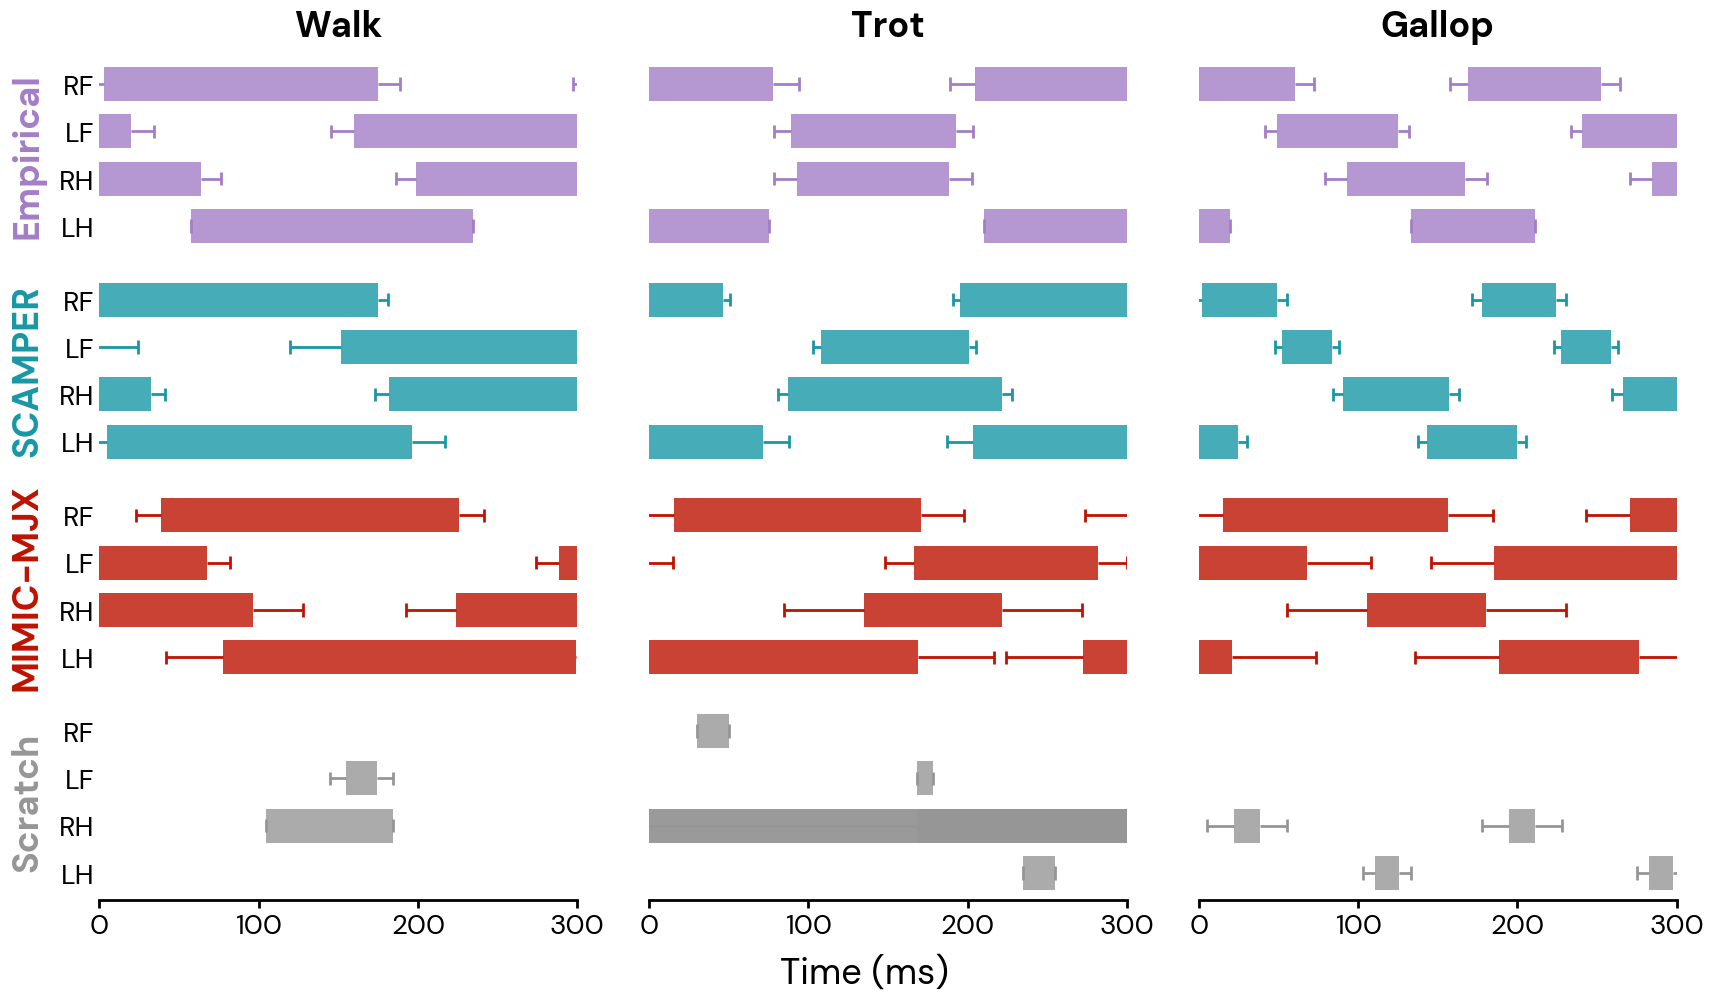

In [ ]:
# ============================================================
# Plot 4x3 grid: columns = Walk, Trot, Gallop;
# rows = Empirical, SCAMPER, MIMIC-MJX, Scratch
# ============================================================

TICK_FONTSIZE = 20
LABEL_FONTSIZE = 26
TITLE_FONTSIZE = 26
ROW_LABEL_FONTSIZE = 26

COLOR_EMPIRICAL = "#A37DC6"
COLOR_SCAMPER = "#1897A5"
COLOR_MIMIC = "#BD1300"
COLOR_SCRATCH = "#969696"

gait_order = ["walk", "trot", "gallop"]
gait_titles = ["Walk", "Trot", "Gallop"]
row_labels = ["Empirical", "SCAMPER", "MIMIC-MJX", "Scratch"]
row_methods = [None, "SCAMPER", "MIMIC-MJX", "Scratch"]
row_colors = [COLOR_EMPIRICAL, COLOR_SCAMPER, COLOR_MIMIC, COLOR_SCRATCH]
n_rows = len(row_labels)

# Map from (method, gait) -> config name
method_gait_to_name = {}
for c in CONFIGS:
    method_gait_to_name[(c["method"], c["gait"])] = c["name"]

display_order = ["LH", "RH", "LF", "RF"]  # top to bottom on each subplot
xlim_ms = 300
cap_half = 0.05
LIMB_SPACING = 0.35  # vertical distance between limb rows (1.0 = default)
rat_time_offset_ms = -250

fig, axes = plt.subplots(n_rows, 3, figsize=(18, 2.4 * n_rows))

for col_idx, gait in enumerate(gait_order):
    for row_idx in range(n_rows):
        ax = axes[row_idx, col_idx]

        if row_idx == 0:
            # --- Empirical ---
            stance_color = COLOR_EMPIRICAL
            ed = empirical_data[gait]
            cycle_len = ed["cycle_len_ms"]
            time_offset = rat_time_offset_ms

            # Display order: LH, RH, LF, RF -> indices into [lh, rh, lf, rf]
            emp_order_idx = [0, 1, 2, 3]  # maps display_order to phases array

            r_start = int(np.floor(-time_offset / cycle_len)) - 1
            r_end = int(np.ceil((xlim_ms - time_offset) / cycle_len)) + 1

            for i, lname in enumerate(display_order):
                idx = emp_order_idx[i]
                bar_start_ms = ed["phases"][idx] * cycle_len
                mean_len_ms = ed["duty_factors"][idx] * cycle_len
                std_len_ms = ed["phases_sd"][idx] * cycle_len

                for r in range(r_start, r_end):
                    x0 = r * cycle_len + time_offset + bar_start_ms
                    ax.barh(
                        i * LIMB_SPACING,
                        mean_len_ms,
                        left=x0,
                        height=0.25,
                        color=stance_color,
                        alpha=0.8,
                        edgecolor="none",
                    )
                    # Error bars
                    right_end = x0 + mean_len_ms + std_len_ms
                    ax.hlines(
                        i * LIMB_SPACING,
                        x0 + mean_len_ms,
                        right_end,
                        colors=stance_color,
                        linewidth=2,
                    )
                    ax.vlines(
                        right_end,
                        i * LIMB_SPACING - cap_half,
                        i * LIMB_SPACING + cap_half,
                        colors=stance_color,
                        linewidth=2,
                    )
                    left_end = x0 - std_len_ms
                    ax.hlines(
                        i * LIMB_SPACING, left_end, x0, colors=stance_color, linewidth=2
                    )
                    ax.vlines(
                        left_end,
                        i * LIMB_SPACING - cap_half,
                        i * LIMB_SPACING + cap_half,
                        colors=stance_color,
                        linewidth=2,
                    )

        else:
            # --- Model rows ---
            method = row_methods[row_idx]
            stance_color = row_colors[row_idx]

            cfg_name = method_gait_to_name[(method, gait)]
            mgp = results[cfg_name]["mean_gait_params"]
            model_cfg = results[cfg_name]["config"]

            cycle_len = mgp["cycle_len_ms"]
            time_offset = model_cfg["mean_gait_time_offset_ms"]

            if method == "SCAMPER" and gait == "gallop":
                time_offset = -260

            r_start = int(np.floor(-time_offset / cycle_len)) - 1
            r_end = int(np.ceil((xlim_ms - time_offset) / cycle_len)) + 1

            for i, lname in enumerate(display_order):
                if lname not in mgp["means"]:
                    continue
                bar_start = mgp["phase_offsets_ms"][lname]
                mean_len = mgp["means"][lname]
                std_len = mgp["stds"][lname]

                for r in range(r_start, r_end):
                    x0 = r * cycle_len + time_offset + bar_start
                    ax.barh(
                        i * LIMB_SPACING,
                        mean_len,
                        left=x0,
                        height=0.25,
                        color=stance_color,
                        alpha=0.8,
                        edgecolor="none",
                    )
                    # Error bars
                    right_end = x0 + mean_len + std_len
                    ax.hlines(
                        i * LIMB_SPACING,
                        x0 + mean_len,
                        right_end,
                        colors=stance_color,
                        linewidth=2,
                    )
                    ax.vlines(
                        right_end,
                        i * LIMB_SPACING - cap_half,
                        i * LIMB_SPACING + cap_half,
                        colors=stance_color,
                        linewidth=2,
                    )
                    left_end = x0 - std_len
                    ax.hlines(
                        i * LIMB_SPACING, left_end, x0, colors=stance_color, linewidth=2
                    )
                    ax.vlines(
                        left_end,
                        i * LIMB_SPACING - cap_half,
                        i * LIMB_SPACING + cap_half,
                        colors=stance_color,
                        linewidth=2,
                    )

        # --- Formatting ---
        ax.set_xlim(0, xlim_ms)
        ax.set_ylim(-0.2, (len(display_order) - 1) * LIMB_SPACING + 0.2)
        ax.grid(False)

        # Only leftmost column shows y-tick labels
        if col_idx == 0:
            ax.set_yticks([j * LIMB_SPACING for j in range(len(display_order))])
            ax.set_yticklabels(display_order, fontsize=TICK_FONTSIZE)
            ax.tick_params(axis="y", length=0)
        else:
            ax.set_yticks([j * LIMB_SPACING for j in range(len(display_order))])
            ax.set_yticklabels([])
            ax.tick_params(axis="y", length=0)

        # Only bottom row shows x-axis
        if row_idx == n_rows - 1:
            ax.tick_params(axis="x", labelsize=TICK_FONTSIZE, width=2, length=6)
        else:
            ax.set_xticklabels([])
            ax.tick_params(axis="x", length=0)

        # Column titles at the top
        if row_idx == 0:
            ax.set_title(
                gait_titles[col_idx], fontsize=TITLE_FONTSIZE, fontweight="bold", pad=15
            )

        # Remove all spines; only bottom row keeps bottom spine
        for spine in ["top", "right", "left"]:
            ax.spines[spine].set_visible(False)
        if row_idx == n_rows - 1:
            ax.spines["bottom"].set_linewidth(2)
        else:
            ax.spines["bottom"].set_visible(False)

        ax.set_ylabel("")

# Row labels on the left
for row_idx, (label, color) in enumerate(zip(row_labels, row_colors)):
    axes[row_idx, 0].annotate(
        label,
        xy=(-0.15, 0.5),
        xycoords="axes fraction",
        fontsize=ROW_LABEL_FONTSIZE,
        fontweight="bold",
        color=color,
        ha="center",
        va="center",
        rotation=90,
    )

fig.text(0.525, -0.03, "Time (ms)", fontsize=LABEL_FONTSIZE, ha="center")
plt.tight_layout()
plt.subplots_adjust(left=0.10, hspace=0.1, wspace=0.15)

# Save
for ext in ["pdf", "svg", "png"]:
    fig.savefig(
        PLOT_DIR / f"combined_gait_diagram_4x3.{ext}",
        dpi=300,
        bbox_inches="tight",
    )
    print(f"Saved: {PLOT_DIR / f'combined_gait_diagram_4x3.{ext}'}")

plt.show()

Saved: /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/combined_gait_diagram_2x3_empirical_scamper.pdf
Saved: /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/combined_gait_diagram_2x3_empirical_scamper.svg
Saved: /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/combined_gait_diagram_2x3_empirical_scamper.png


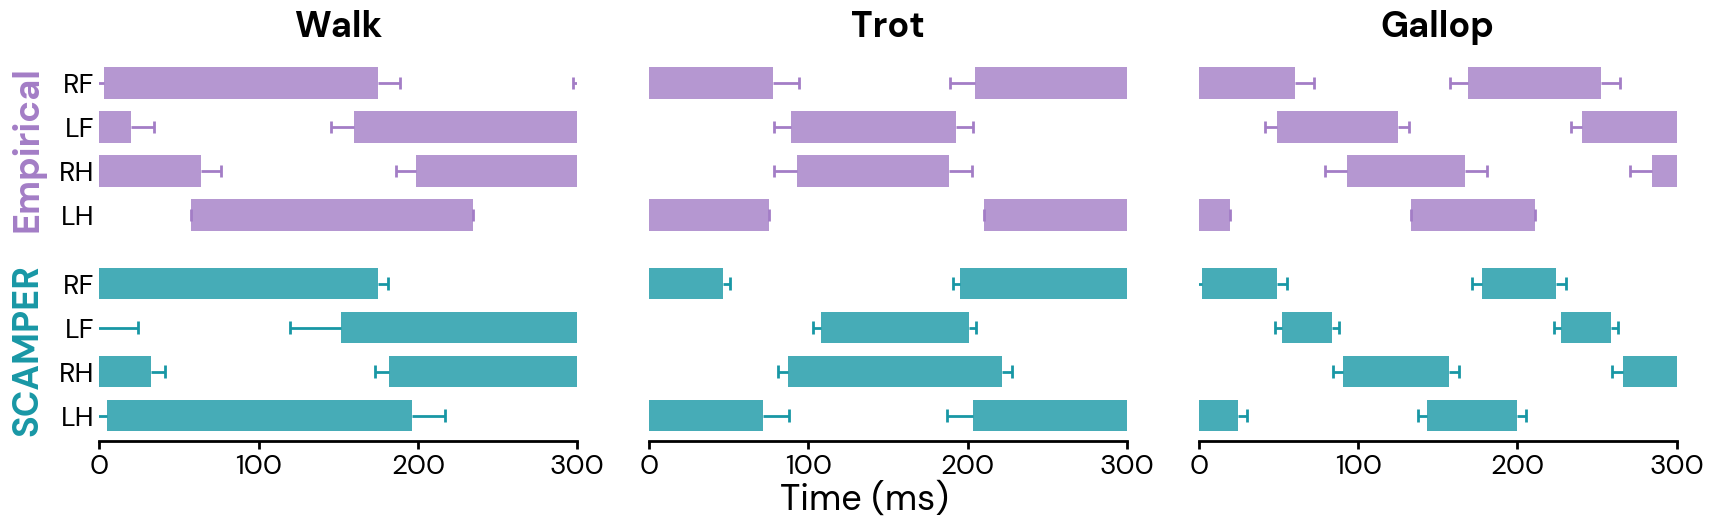

In [ ]:
# ============================================================
# Plot 2x3 grid: columns = Walk, Trot, Gallop; rows = Empirical, SCAMPER
# ============================================================

TICK_FONTSIZE = 20
LABEL_FONTSIZE = 26
TITLE_FONTSIZE = 26
ROW_LABEL_FONTSIZE = 26

COLOR_EMPIRICAL = "#A37DC6"
COLOR_SCAMPER = "#1897A5"

gait_order = ["walk", "trot", "gallop"]
gait_titles = ["Walk", "Trot", "Gallop"]
row_labels = ["Empirical", "SCAMPER"]
row_colors = [COLOR_EMPIRICAL, COLOR_SCAMPER]

# Map from (method, gait) -> config name
method_gait_to_name = {}
for c in CONFIGS:
    method_gait_to_name[(c["method"], c["gait"])] = c["name"]

display_order = ["LH", "RH", "LF", "RF"]  # top to bottom on each subplot
xlim_ms = 300
cap_half = 0.05
LIMB_SPACING = 0.35  # vertical distance between limb rows (1.0 = default)
rat_time_offset_ms = -250

fig, axes = plt.subplots(2, 3, figsize=(18, 5))

for col_idx, gait in enumerate(gait_order):
    for row_idx in range(2):
        ax = axes[row_idx, col_idx]

        if row_idx == 0:
            # --- Empirical ---
            stance_color = COLOR_EMPIRICAL
            ed = empirical_data[gait]
            cycle_len = ed["cycle_len_ms"]
            time_offset = rat_time_offset_ms

            emp_order_idx = [0, 1, 2, 3]  # maps display_order to phases array

            r_start = int(np.floor(-time_offset / cycle_len)) - 1
            r_end = int(np.ceil((xlim_ms - time_offset) / cycle_len)) + 1

            for i, lname in enumerate(display_order):
                idx = emp_order_idx[i]
                bar_start_ms = ed["phases"][idx] * cycle_len
                mean_len_ms = ed["duty_factors"][idx] * cycle_len
                std_len_ms = ed["phases_sd"][idx] * cycle_len

                for r in range(r_start, r_end):
                    x0 = r * cycle_len + time_offset + bar_start_ms
                    ax.barh(
                        i * LIMB_SPACING,
                        mean_len_ms,
                        left=x0,
                        height=0.25,
                        color=stance_color,
                        alpha=0.8,
                        edgecolor="none",
                    )
                    right_end = x0 + mean_len_ms + std_len_ms
                    ax.hlines(
                        i * LIMB_SPACING,
                        x0 + mean_len_ms,
                        right_end,
                        colors=stance_color,
                        linewidth=2,
                    )
                    ax.vlines(
                        right_end,
                        i * LIMB_SPACING - cap_half,
                        i * LIMB_SPACING + cap_half,
                        colors=stance_color,
                        linewidth=2,
                    )
                    left_end = x0 - std_len_ms
                    ax.hlines(
                        i * LIMB_SPACING, left_end, x0, colors=stance_color, linewidth=2
                    )
                    ax.vlines(
                        left_end,
                        i * LIMB_SPACING - cap_half,
                        i * LIMB_SPACING + cap_half,
                        colors=stance_color,
                        linewidth=2,
                    )

        else:
            # --- SCAMPER ---
            method = "SCAMPER"
            stance_color = COLOR_SCAMPER

            cfg_name = method_gait_to_name[(method, gait)]
            mgp = results[cfg_name]["mean_gait_params"]
            model_cfg = results[cfg_name]["config"]

            cycle_len = mgp["cycle_len_ms"]
            time_offset = model_cfg["mean_gait_time_offset_ms"]

            if method == "SCAMPER" and gait == "gallop":
                time_offset = -260

            r_start = int(np.floor(-time_offset / cycle_len)) - 1
            r_end = int(np.ceil((xlim_ms - time_offset) / cycle_len)) + 1

            for i, lname in enumerate(display_order):
                if lname not in mgp["means"]:
                    continue
                bar_start = mgp["phase_offsets_ms"][lname]
                mean_len = mgp["means"][lname]
                std_len = mgp["stds"][lname]

                for r in range(r_start, r_end):
                    x0 = r * cycle_len + time_offset + bar_start
                    ax.barh(
                        i * LIMB_SPACING,
                        mean_len,
                        left=x0,
                        height=0.25,
                        color=stance_color,
                        alpha=0.8,
                        edgecolor="none",
                    )
                    right_end = x0 + mean_len + std_len
                    ax.hlines(
                        i * LIMB_SPACING,
                        x0 + mean_len,
                        right_end,
                        colors=stance_color,
                        linewidth=2,
                    )
                    ax.vlines(
                        right_end,
                        i * LIMB_SPACING - cap_half,
                        i * LIMB_SPACING + cap_half,
                        colors=stance_color,
                        linewidth=2,
                    )
                    left_end = x0 - std_len
                    ax.hlines(
                        i * LIMB_SPACING, left_end, x0, colors=stance_color, linewidth=2
                    )
                    ax.vlines(
                        left_end,
                        i * LIMB_SPACING - cap_half,
                        i * LIMB_SPACING + cap_half,
                        colors=stance_color,
                        linewidth=2,
                    )

        # --- Formatting ---
        ax.set_xlim(0, xlim_ms)
        ax.set_ylim(-0.2, (len(display_order) - 1) * LIMB_SPACING + 0.2)
        ax.grid(False)

        if col_idx == 0:
            ax.set_yticks([j * LIMB_SPACING for j in range(len(display_order))])
            ax.set_yticklabels(display_order, fontsize=TICK_FONTSIZE)
            ax.tick_params(axis="y", length=0)
        else:
            ax.set_yticks([j * LIMB_SPACING for j in range(len(display_order))])
            ax.set_yticklabels([])
            ax.tick_params(axis="y", length=0)

        # Bottom row (SCAMPER) shows x-axis
        if row_idx == 1:
            ax.tick_params(axis="x", labelsize=TICK_FONTSIZE, width=2, length=6)
        else:
            ax.set_xticklabels([])
            ax.tick_params(axis="x", length=0)

        if row_idx == 0:
            ax.set_title(
                gait_titles[col_idx], fontsize=TITLE_FONTSIZE, fontweight="bold", pad=15
            )

        for spine in ["top", "right", "left"]:
            ax.spines[spine].set_visible(False)
        if row_idx == 1:
            ax.spines["bottom"].set_linewidth(2)
        else:
            ax.spines["bottom"].set_visible(False)

        ax.set_ylabel("")

# Row labels on the left
for row_idx, (label, color) in enumerate(zip(row_labels, row_colors)):
    axes[row_idx, 0].annotate(
        label,
        xy=(-0.15, 0.5),
        xycoords="axes fraction",
        fontsize=ROW_LABEL_FONTSIZE,
        fontweight="bold",
        color=color,
        ha="center",
        va="center",
        rotation=90,
    )

fig.text(0.525, -0.03, "Time (ms)", fontsize=LABEL_FONTSIZE, ha="center")
plt.tight_layout()
plt.subplots_adjust(left=0.10, hspace=0.1, wspace=0.15)

for ext in ["pdf", "svg", "png"]:
    fig.savefig(
        PLOT_DIR / f"combined_gait_diagram_2x3_empirical_scamper.{ext}",
        dpi=300,
        bbox_inches="tight",
    )
    print(f"Saved: {PLOT_DIR / f'combined_gait_diagram_2x3_empirical_scamper.{ext}'}")

plt.show()

## Gait Metrics Summary Table

In [ ]:
# ============================================================
# Build master comparison table: Empirical vs SCAMPER vs MIMIC-MJX vs Scratch
# |Δμ| per metric for interpretability, |Δμ|/σ (empirical σ) for summaries
# ============================================================

limb_order = ["LH", "RH", "LF", "RF"]


def compute_full_metrics(mgp, ctrl_dt_ms):
    """Compute all gait metrics from mean_gait_params dict."""
    means = mgp["means"]
    stds_ms = mgp["stds"]
    stance_durations = mgp["stance_durations"]
    stance_starts = mgp["stance_starts"]
    stride_periods = mgp["stride_periods"]
    mean_stride = mgp["mean_stride"]
    cycle_ms = mgp["cycle_len_ms"]

    m = {}
    all_stride_ts = np.concatenate(
        [stride_periods[n] for n in limb_order if len(stride_periods[n]) > 0]
    )
    m["stride_duration_ms"] = (
        cycle_ms,
        all_stride_ts.std() * ctrl_dt_ms if len(all_stride_ts) > 1 else 0.0,
    )
    step_freqs = (
        1000.0 / (all_stride_ts * ctrl_dt_ms)
        if len(all_stride_ts) > 0
        else np.array([0.0])
    )
    m["step_freq_hz"] = (step_freqs.mean(), step_freqs.std())

    for name in limb_order:
        m[f"stance_{name}_ms"] = (means.get(name, 0.0), stds_ms.get(name, 0.0))
        n_strides = len(stride_periods.get(name, []))
        if n_strides > 0:
            swing_ts = stride_periods[name] - stance_durations[name][:n_strides]
            m[f"swing_{name}_ms"] = (
                swing_ts.mean() * ctrl_dt_ms,
                swing_ts.std() * ctrl_dt_ms,
            )
        else:
            m[f"swing_{name}_ms"] = (cycle_ms - means.get(name, 0.0), 0.0)
        m[f"duty_{name}"] = (
            means.get(name, 0.0) / cycle_ms,
            stds_ms.get(name, 0.0) / cycle_ms,
        )

    n_sym = min(
        len(stride_periods.get("LH", [])),
        len(stride_periods.get("RH", [])),
        len(stance_durations.get("LH", [])),
        len(stance_durations.get("RH", [])),
    )
    if n_sym > 0:
        lh_duty = stance_durations["LH"][:n_sym] / stride_periods["LH"][:n_sym]
        rh_duty = stance_durations["RH"][:n_sym] / stride_periods["RH"][:n_sym]
        tsym = (lh_duty - rh_duty) / (lh_duty + rh_duty)
        m["temp_sym"] = (tsym.mean(), tsym.std())
    else:
        m["temp_sym"] = (0.0, 0.0)

    for name in limb_order:
        per_bout = []
        if len(stance_starts.get("LH", [])) > 0:
            for s in stance_starts.get(name, []):
                diffs = s - stance_starts["LH"]
                valid = diffs[diffs >= 0]
                if len(valid) > 0:
                    per_bout.append(valid.min())
        per_bout = np.array(per_bout)
        if len(per_bout) > 0:
            phase_frac = (per_bout % mean_stride) / mean_stride
            m[f"phase_{name}"] = (phase_frac.mean(), phase_frac.std())
        else:
            m[f"phase_{name}"] = (0.0, 0.0)

    return m


def compute_empirical_metrics(ed, df_gait):
    """Compute all gait metrics from empirical data."""
    m = {}
    cycle_ms = ed["cycle_len_ms"]
    m["stride_duration_ms"] = (cycle_ms, df_gait.phase_dur.std() * 1000)
    step_freqs = 1000.0 / (df_gait.phase_dur * 1000)
    m["step_freq_hz"] = (step_freqs.mean(), step_freqs.std())
    duty_cols = {
        "LH": "duty_factor_lh",
        "RH": "duty_factor_rh",
        "LF": "duty_factor_lf",
        "RF": "duty_factor_rf",
    }
    for name in limb_order:
        stance_per_stride = df_gait[duty_cols[name]] * df_gait.phase_dur * 1000
        m[f"stance_{name}_ms"] = (stance_per_stride.mean(), stance_per_stride.std())
        swing_per_stride = df_gait.phase_dur * 1000 - stance_per_stride
        m[f"swing_{name}_ms"] = (swing_per_stride.mean(), swing_per_stride.std())
        m[f"duty_{name}"] = (
            df_gait[duty_cols[name]].mean(),
            df_gait[duty_cols[name]].std(),
        )
    tsym = (df_gait.duty_factor_lh - df_gait.duty_factor_rh) / (
        df_gait.duty_factor_lh + df_gait.duty_factor_rh
    )
    m["temp_sym"] = (tsym.mean(), tsym.std())
    m["phase_LH"] = (0.0, 0.0)
    m["phase_RH"] = (ed["phases"][1], ed["phases_sd"][1])
    m["phase_LF"] = (ed["phases"][2], ed["phases_sd"][2])
    m["phase_RF"] = (ed["phases"][3], ed["phases_sd"][3])
    return m


metric_defs = [
    ("Stride Duration (ms)", "stride_duration_ms", 0),
    ("Step Frequency (Hz)", "step_freq_hz", 2),
    ("Stance LH (ms)", "stance_LH_ms", 0),
    ("Stance RH (ms)", "stance_RH_ms", 0),
    ("Stance LF (ms)", "stance_LF_ms", 0),
    ("Stance RF (ms)", "stance_RF_ms", 0),
    ("Swing LH (ms)", "swing_LH_ms", 0),
    ("Swing RH (ms)", "swing_RH_ms", 0),
    ("Swing LF (ms)", "swing_LF_ms", 0),
    ("Swing RF (ms)", "swing_RF_ms", 0),
    ("Duty Factor LH", "duty_LH", 3),
    ("Duty Factor RH", "duty_RH", 3),
    ("Duty Factor LF", "duty_LF", 3),
    ("Duty Factor RF", "duty_RF", 3),
    ("Temporal Symmetry (hind)", "temp_sym", 4),
    ("Phase RH rel. LH", "phase_RH", 3),
    ("Phase LF rel. LH", "phase_LF", 3),
    ("Phase RF rel. LH", "phase_RF", 3),
]

coordination_keys = {"temp_sym", "phase_RH", "phase_LF", "phase_RF"}
gait_pattern_keys = {
    "phase_RH",
    "phase_LF",
    "phase_RF",
    "duty_LH",
    "duty_RH",
    "duty_LF",
    "duty_RF",
}

df_phases_all = pd.read_hdf(EMPIRICAL_DATA_PATH, key="df_phases")
gait_to_filter = EMPIRICAL_GAIT_FILTER
gait_order = ["walk", "trot", "gallop"]
gait_titles = {"walk": "Walk", "trot": "Trot", "gallop": "Gallop"}

method_gait_to_name = {}
for c in CONFIGS:
    method_gait_to_name[(c["method"], c["gait"])] = c["name"]

# Methods compared against the empirical reference (display order)
COMPARE_METHODS = ["SCAMPER", "MIMIC-MJX", "Scratch"]

all_tables = []

for gait in gait_order:
    gait_label = gait_titles[gait]

    filt = gait_to_filter[gait]
    df_gait = df_phases_all[
        (df_phases_all.SCI == "intact") & (df_phases_all.gaits_all2 == filt)
    ][
        [
            "LR_h",
            "hl",
            "diag",
            "duty_factor_lh",
            "duty_factor_rh",
            "duty_factor_lf",
            "duty_factor_rf",
            "phase_dur",
        ]
    ].dropna()
    emp_m = compute_empirical_metrics(empirical_data[gait], df_gait)

    method_metrics = {}
    for method in COMPARE_METHODS:
        cfg_name = method_gait_to_name[(method, gait)]
        mgp = results[cfg_name]["mean_gait_params"]
        ctrl_dt_ms = results[cfg_name]["ctrl_dt"] * 1000
        method_metrics[method] = compute_full_metrics(mgp, ctrl_dt_ms)

    dsig_all = {m: [] for m in COMPARE_METHODS}
    dsig_coord = {m: [] for m in COMPARE_METHODS}
    dsig_pattern = {m: [] for m in COMPARE_METHODS}

    for display_name, key, dp in metric_defs:
        e_mean, e_std = emp_m[key]
        e_str = f"{e_mean:.{dp}f} ± {e_std:.{dp}f}"

        row = {"Gait": gait_label, "Metric": display_name, "Empirical": e_str}

        for method in COMPARE_METHODS:
            mm_mean, mm_std = method_metrics[method][key]
            row[method] = f"{mm_mean:.{dp}f} ± {mm_std:.{dp}f}"
            mm_abs = abs(mm_mean - e_mean)
            mm_dsig = mm_abs / e_std if e_std > 0 else np.inf
            row[f"|Δμ| {method}"] = f"{mm_abs:.{dp}f}"
            row[f"|Δμ|/σ {method}"] = f"{mm_dsig:.2f}"

            if np.isfinite(mm_dsig):
                dsig_all[method].append(mm_dsig)
            if key in coordination_keys and np.isfinite(mm_dsig):
                dsig_coord[method].append(mm_dsig)
            if key in gait_pattern_keys and np.isfinite(mm_dsig):
                dsig_pattern[method].append(mm_dsig)

        all_tables.append(row)

    def _summary(label, dsig_dict):
        row = {
            "Gait": gait_label,
            "Metric": label,
            "Empirical": "",
        }
        for method in COMPARE_METHODS:
            row[method] = ""
            row[f"|Δμ| {method}"] = ""
            arr = np.array(dsig_dict[method])
            row[f"|Δμ|/σ {method}"] = (
                f"{arr.mean():.2f}" if len(arr) > 0 else ""
            )
        return row

    all_tables.append(_summary("Mean |Δμ|/σ (all)", dsig_all))
    all_tables.append(
        _summary("Mean |Δμ|/σ (coordination)", dsig_coord)
    )
    all_tables.append(
        _summary("Mean |Δμ|/σ (gait pattern)", dsig_pattern)
    )

# Reorder columns: Gait, Metric, Empirical, then per-method blocks
col_order = ["Gait", "Metric", "Empirical"]
for method in COMPARE_METHODS:
    col_order.append(method)
for method in COMPARE_METHODS:
    col_order.append(f"|Δμ| {method}")
for method in COMPARE_METHODS:
    col_order.append(f"|Δμ|/σ {method}")

master_df = pd.DataFrame(all_tables)[col_order]


def highlight_best(row, prefix):
    """Bold the column with the smallest numeric value among the prefixed columns."""
    cols = list(row.index)
    styles = [""] * len(cols)
    method_cols = [f"{prefix}{m}" for m in COMPARE_METHODS]
    values = []
    for c in method_cols:
        try:
            v = float(row[c])
            values.append((c, v))
        except (ValueError, KeyError):
            values.append((c, np.inf))
    finite_values = [(c, v) for c, v in values if np.isfinite(v)]
    if not finite_values:
        return styles
    best_val = min(v for _, v in finite_values)
    n_at_min = sum(1 for _, v in finite_values if v == best_val)
    if n_at_min == 1:
        best_col = next(c for c, v in finite_values if v == best_val)
        styles[cols.index(best_col)] = "font-weight: bold"
    return styles


def highlight_better(row):
    styles_abs = highlight_best(row, "|Δμ| ")
    styles_sig = highlight_best(row, "|Δμ|/σ ")
    return [a if a else b for a, b in zip(styles_abs, styles_sig)]


print("|Δμ| = absolute difference between model mean and empirical mean")
print("|Δμ|/σ = |Δμ| / σ_empirical  (lower = closer, scale-normalized)")
print("Summary uses mean |Δμ|/σ across metrics (weights errors by empirical precision)")
print()

styled = master_df.style.apply(highlight_better, axis=1)
display(styled)

print()
print(master_df.to_string(index=False))


|Δμ| = absolute difference between model mean and empirical mean
|Δμ|/σ = |Δμ| / σ_empirical  (lower = closer, scale-normalized)
Summary uses mean |Δμ|/σ across metrics (weights errors by empirical precision)



,Gait,Metric,Empirical,SCAMPER,MIMIC-MJX,Scratch,|Δμ| SCAMPER,|Δμ| MIMIC-MJX,|Δμ| Scratch,|Δμ|/σ SCAMPER,|Δμ|/σ MIMIC-MJX,|Δμ|/σ Scratch
0,Walk,Stride Duration (ms),308 ± 91,332 ± 16,374 ± 23,255 ± 293,25,66,53,0.27,0.73,0.58
1,Walk,Step Frequency (Hz),3.46 ± 0.75,3.02 ± 0.15,2.69 ± 0.26,4.61 ± 2.62,0.44,0.76,1.16,0.58,1.02,1.53
2,Walk,Stance LH (ms),182 ± 82,191 ± 21,221 ± 36,223 ± 295,9,39,41,0.11,0.48,0.50
3,Walk,Stance RH (ms),175 ± 66,183 ± 9,247 ± 31,80 ± 0,8,72,95,0.12,1.09,1.45
4,Walk,Stance LF (ms),171 ± 71,172 ± 32,153 ± 15,20 ± 10,1,18,151,0.02,0.25,2.12
5,Walk,Stance RF (ms),174 ± 69,183 ± 6,187 ± 16,0 ± 0,9,13,174,0.13,0.19,2.53
6,Walk,Swing LH (ms),125 ± 20,144 ± 5,152 ± 10,150 ± 45,19,26,24,0.96,1.33,1.23
7,Walk,Swing RH (ms),133 ± 31,148 ± 5,123 ± 8,175 ± 0,16,9,42,0.51,0.29,1.37
8,Walk,Swing LF (ms),136 ± 25,152 ± 7,219 ± 22,120 ± 0,16,83,16,0.63,3.33,0.66
9,Walk,Swing RF (ms),133 ± 30,149 ± 3,184 ± 7,255 ± 0,15,51,121,0.50,1.67,3.99



  Gait                     Metric        Empirical          SCAMPER        MIMIC-MJX          Scratch |Δμ| SCAMPER |Δμ| MIMIC-MJX |Δμ| Scratch |Δμ|/σ SCAMPER |Δμ|/σ MIMIC-MJX |Δμ|/σ Scratch
  Walk       Stride Duration (ms)         308 ± 91         332 ± 16         374 ± 23        255 ± 293           25             66           53           0.27             0.73           0.58
  Walk        Step Frequency (Hz)      3.46 ± 0.75      3.02 ± 0.15      2.69 ± 0.26      4.61 ± 2.62         0.44           0.76         1.16           0.58             1.02           1.53
  Walk             Stance LH (ms)         182 ± 82         191 ± 21         221 ± 36        223 ± 295            9             39           41           0.11             0.48           0.50
  Walk             Stance RH (ms)         175 ± 66          183 ± 9         247 ± 31           80 ± 0            8             72           95           0.12             1.09           1.45
  Walk             Stance LF (ms)         171 ± 7

In [22]:
# ============================================================
# Render NAME with stylized swing/stance gait OVERLAY (configurable HD)
# Optionally re-renders the mujoco frames at any resolution from the cached npz.
# Without re-render, frames come from the 640x480 cached MP4 — bumping the
# composite figure DPI past ~2x just blurs that source.
# ============================================================
import functools
import gc
from types import SimpleNamespace

import imageio
import jax
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.patheffects as path_effects
from IPython.display import Video, display
from matplotlib.animation import FuncAnimation
from matplotlib.transforms import blended_transform_factory

mpl.rcParams["font.family"] = "DM Sans"

NAME = "Scratch_S7e-1"
VIDEO_IN = DATA_BASE_DIR / NAME / f"{NAME}_rollout.mp4"
VIDEO_OUT = PLOT_DIR / f"{NAME}_with_gait.mp4"

# ============== Resolution knobs ==============
HI_RES_RERENDER = True  # True -> rebuild env, re-render mujoco frames from npz
RERENDER_W, RERENDER_H = 1920, 1440  # mujoco render resolution (keep 4:3)
TARGET_W, TARGET_H = 1920, 1440  # composite output resolution (figsize_in * dpi)
COMPOSITE_DPI = 100
VISIBLE = 120  # frames shown in the scrolling window
# ===============================================

# ----------------------------------------------------------
# Acquire frames: re-render at high res, or load the cached MP4
# ----------------------------------------------------------
if HI_RES_RERENDER:
    # NAME is part of the key so switching checkpoints invalidates stale frames.
    cache_key = (NAME, RERENDER_W, RERENDER_H)
    if globals().get("_frames_hires_key") != cache_key:
        # Drop any prior cache before allocating new frames so the old buffer
        # can be reclaimed instead of doubling peak memory.
        if "_frames_hires" in globals():
            del globals()["_frames_hires"]
            globals().pop("_frames_hires_key", None)
            gc.collect()

        print(f"Rebuilding env and re-rendering at {RERENDER_W}x{RERENDER_H}...")
        cfg_render = next(c for c in CONFIGS if c["name"] == NAME)
        ckpt_info = load_task_transfer_metadata(
            cfg_render["checkpoint_path"], step=cfg_render["checkpoint_step"]
        )
        config_render = ckpt_info["config"]
        ckpt_cfg = config_render["checkpoint_config"]
        mode_render = config_render["mode"]

        # Frozen networks (only decoder/prior are needed by the wrapper for the .render path)
        step_prefix = "DistillNetwork" if mode_render == "distill" else "PriorNetwork"
        _, prior_params, decoder_params, normalizer_params, _ = load_prior_checkpoint(
            config_render["checkpoint"]["path"],
            config_render["checkpoint"]["step"],
            step_prefix=step_prefix,
        )

        latent_size = ckpt_cfg["network_config"]["intention_size"]
        proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]

        env_cfg = maintain_velocity.default_config()
        xml_variant = config_render["env"].get("xml_variant", "full-collisions")
        env_cfg.walker_xml_path = {
            "limited-collisions": rodent_consts.RODENT_XML_PATH,
            "full-collisions": rodent_consts.RODENT_FULL_COLLISION_XML,
            "no-tail-collisions": rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
        }[xml_variant]
        env_cfg.mujoco_impl = config_render["env"].get("mujoco_impl", "jax")
        env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
        env_cfg.init_z = config_render["env"]["init_z"]
        env_cfg.target_speed = config_render["env"]["target_speed"]

        decoder_fn = make_decoder_inference_fn(
            decoder_params, normalizer_params, ckpt_cfg
        )
        base_env_render = maintain_velocity.MaintainVelocity(config=env_cfg)

        # Mirror cell 5's mode dispatch: only prior_decoder/distill use the
        # prior+decoder wrapper. decoder_only and scratch use simpler wrappers
        # whose configs don't carry deterministic_prior/noise_logvar.
        if mode_render == "decoder_only":
            env_render = DecoderHighLevelWrapper(
                base_env_render, decoder_fn, latent_size, proprio_size
            )
        elif mode_render == "scratch":
            env_render = FlatObsWrapper(base_env_render)
        elif mode_render in ("prior_decoder", "distill"):
            prior_fn = make_prior_inference_fn(
                prior_params, normalizer_params, ckpt_cfg
            )
            mode_cfg_render = config_render.get(
                mode_render, config_render.get("prior_decoder", {})
            )
            env_render = PriorDecoderHighLevelWrapper(
                base_env_render,
                prior_fn,
                decoder_fn,
                latent_size,
                proprio_size,
                deterministic_prior=mode_cfg_render["deterministic_prior"],
                noise_logvar=mode_cfg_render["noise_logvar"],
            )
        else:
            raise ValueError(f"Unknown mode: {mode_render}")

        # Reconstruct rollout from cached npz (mirrors cell 5)
        run_id = cfg_render["checkpoint_path"].rsplit("/", 1)[-1]
        save_path = (
            DATA_BASE_DIR
            / NAME
            / f"rollout_{NAME}_step{cfg_render['checkpoint_step']}_seed{cfg_render['seed']}_{run_id}.npz"
        )
        loaded = np.load(save_path)

        _jit_reset = jax.jit(env_render.reset)
        _ref_state = _jit_reset(jax.random.PRNGKey(99))
        _default_mocap_pos = np.array(_ref_state.data.mocap_pos)
        _default_mocap_quat = np.array(_ref_state.data.mocap_quat)
        _default_xfrc = np.zeros_like(np.array(_ref_state.data.xfrc_applied))

        rollout_render = []
        for i in range(len(loaded["qpos"])):
            d = SimpleNamespace(
                qpos=loaded["qpos"][i],
                qvel=loaded["qvel"][i],
                xpos=loaded["xpos"][i],
                sensordata=loaded["sensordata"][i],
                mocap_pos=_default_mocap_pos,
                mocap_quat=_default_mocap_quat,
                xfrc_applied=_default_xfrc,
            )
            s = SimpleNamespace(
                data=d,
                obs=loaded["obs"][i],
                reward=loaded["reward"][i],
                done=loaded["done"][i],
            )
            rollout_render.append(s)

        print(
            f"  Rendering {len(rollout_render)} frames @ {RERENDER_W}x{RERENDER_H} (slow)..."
        )
        frames = env_render.render(
            rollout_render, camera=RENDER_CAMERA, height=RERENDER_H, width=RERENDER_W
        )
        print("  Render done.")

        _frames_hires = frames
        _frames_hires_key = cache_key

        # Free the env, params, closures, and rollout buffers — they aren't
        # needed past this point and together hold hundreds of MB. Some names
        # (prior_fn, mode_cfg_render) only exist in the prior_decoder/distill
        # branch, so pop them from globals defensively.
        loaded.close()
        del (
            env_render,
            base_env_render,
            rollout_render,
            _jit_reset,
            _ref_state,
            _default_mocap_pos,
            _default_mocap_quat,
            _default_xfrc,
            decoder_fn,
            prior_params,
            decoder_params,
            normalizer_params,
            ckpt_info,
            config_render,
            ckpt_cfg,
            cfg_render,
            env_cfg,
            loaded,
        )
        for _opt in ("prior_fn", "mode_cfg_render"):
            globals().pop(_opt, None)
        jax.clear_caches()
        gc.collect()
    else:
        print(f"Reusing cached high-res frames @ {RERENDER_W}x{RERENDER_H}.")
        frames = _frames_hires
else:
    print(f"Loading cached low-res frames from {VIDEO_IN}...")
    reader = imageio.get_reader(str(VIDEO_IN))
    frames = [f for f in reader]
    reader.close()

# ----------------------------------------------------------
# Build swing/stance overlay and animate
# ----------------------------------------------------------
contact_barcode = results[NAME][
    "contact_barcode"
]  # [4, T] source order: [RH, RF, LF, LH]

T = min(len(frames), contact_barcode.shape[1])
frames = frames[:T]
contact_barcode = contact_barcode[:, :T]

LIMB_LABELS = ["RF", "LF", "RH", "LH"]
row_perm = [1, 2, 0, 3]
contact_reord = contact_barcode[row_perm]

LIMB_COLORS = [
    tuple(c / 255 for c in (0, 170, 188)),  # RF blue
    tuple(c / 255 for c in (148, 103, 189)),  # LF purple
    tuple(c / 255 for c in (189, 19, 0)),  # RH red
    tuple(c / 255 for c in (150, 150, 150)),  # LH grey
]

ROW_PX, GAP_PX = 44, 12
STRIP_H = 4 * ROW_PX + 3 * GAP_PX
strip_full = np.zeros((STRIP_H, T, 4))
for i, color in enumerate(LIMB_COLORS):
    y0 = i * (ROW_PX + GAP_PX)
    y1 = y0 + ROW_PX
    stance = contact_reord[i] > 0
    strip_full[y0:y1, stance, :3] = color
    strip_full[y0:y1, stance, 3] = 1.0

fig = plt.figure(
    figsize=(TARGET_W / COMPOSITE_DPI, TARGET_H / COMPOSITE_DPI), dpi=COMPOSITE_DPI
)

ax_video = fig.add_axes([0, 0, 1, 1])
ax_video.set_axis_off()
video_im = ax_video.imshow(frames[0], aspect="auto")

BAR_LEFT, BAR_BOT, BAR_W, BAR_H = 0.06, 0.08, 0.88, 0.22
ax_bar = fig.add_axes([BAR_LEFT, BAR_BOT, BAR_W, BAR_H])
ax_bar.set_axis_off()
ax_bar.patch.set_alpha(0)
ax_bar.set_xlim(0, VISIBLE)
ax_bar.set_ylim(STRIP_H + 5, -5)

init_rgba = np.zeros((STRIP_H, VISIBLE, 4))
bar_im = ax_bar.imshow(
    init_rgba, aspect="auto", interpolation="nearest", extent=[0, VISIBLE, STRIP_H, 0]
)

# Vertical red emergence line — bars appear here and slide leftward
ax_bar.axvline(VISIBLE, color="#FF3B30", lw=8, alpha=0.95, zorder=5)

trans = blended_transform_factory(ax_bar.transAxes, ax_bar.transData)
for i, lbl in enumerate(LIMB_LABELS):
    y_center = i * (ROW_PX + GAP_PX) + ROW_PX / 2
    txt = ax_bar.text(
        -0.015,
        y_center,
        lbl,
        transform=trans,
        ha="right",
        va="center",
        fontsize=40,
        fontweight="bold",
        color="white",
        fontfamily="DM Sans",
        clip_on=False,
    )
    txt.set_path_effects([path_effects.withStroke(linewidth=4.5, foreground="black")])


def update(t):
    video_im.set_data(frames[t])
    visible = np.zeros((STRIP_H, VISIBLE, 4))
    start = max(0, t - VISIBLE + 1)
    n_show = t - start + 1
    visible[:, VISIBLE - n_show :, :] = strip_full[:, start : t + 1, :]
    bar_im.set_data(visible)
    return [video_im, bar_im]


anim = FuncAnimation(fig, update, frames=T, interval=1000.0 / RENDER_FPS, blit=True)
print(f"Saving composite video ({TARGET_W}x{TARGET_H}) to {VIDEO_OUT}...")
anim.save(str(VIDEO_OUT), writer="ffmpeg", fps=RENDER_FPS, dpi=COMPOSITE_DPI)
plt.close(fig)
print("  Saved.")

display(Video(str(VIDEO_OUT), embed=True))

# ----------------------------------------------------------
# Free working memory so this cell can be re-run for another checkpoint
# without OOM-ing the kernel. The composite figure, animation, and the
# cached high-res frames together dominate footprint (T * W * H * 3 bytes
# for the frame list plus matplotlib's internal copies).
# ----------------------------------------------------------
plt.close("all")
for _name in (
    "frames",
    "_frames_hires",
    "strip_full",
    "init_rgba",
    "contact_barcode",
    "contact_reord",
    "anim",
    "fig",
    "ax_video",
    "ax_bar",
    "video_im",
    "bar_im",
    "update",
):
    globals().pop(_name, None)
globals().pop("_frames_hires_key", None)
jax.clear_caches()
gc.collect()
print("Cleaned up render state — safe to switch NAME and re-run.")

Rebuilding env and re-rendering at 1920x1440...
  Rendering 1001 frames @ 1920x1440 (slow)...


100%|██████████| 1001/1001 [00:06<00:00, 166.23it/s]


  Render done.
Saving composite video (1920x1440) to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/Scratch_S7e-1_with_gait.mp4...
  Saved.


Cleaned up render state — safe to switch NAME and re-run.
